# Spambase · filtrer les courriels

Peut-on repérer les spams de ce corpus à partir de 57 mesures, tout en limitant les messages légitimes bloqués ? La documentation souligne le coût des faux positifs. Le critère principal sera le **F₀,₅**, qui accorde davantage de poids à la précision. Une fois la famille choisie, on évalue aussi une règle de blocage visant au moins 98 % de précision en validation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ml_workflow as mlw

mlw.get_environment_info()

{'python': '3.12.14',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2'}

## 1. Data import and exploration

In [2]:
DATA_PATH = Path("datasets/spam/spambase.data")
X, y = mlw.load_dataset("SPAM", DATA_PATH)

4,601 observations, 57 features
Missing feature values: 0


,count,mean,std,min,25%,50%,75%,max,dtype,missing
word_freq_415,4601.0,0.048,0.329,0.0,0.0,0.0,0.0,4.76,float64,0
word_freq_857,4601.0,0.047,0.329,0.0,0.0,0.0,0.0,4.76,float64,0
capital_run_length_longest,4601.0,52.173,194.891,1.0,6.0,15.0,43.0,9989.00,int64,0


,count,proportion
Class,,
0,2788,60.6%
1,1813,39.4%


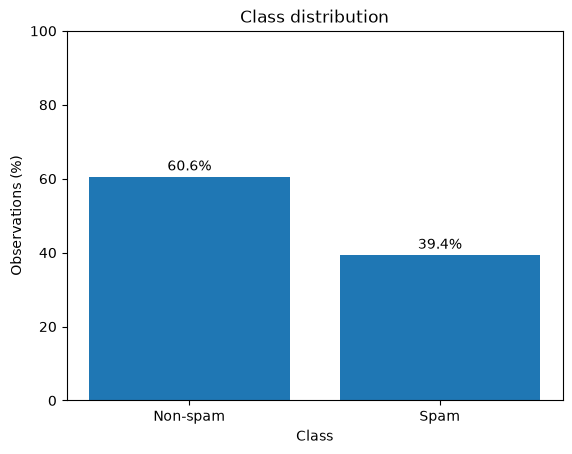

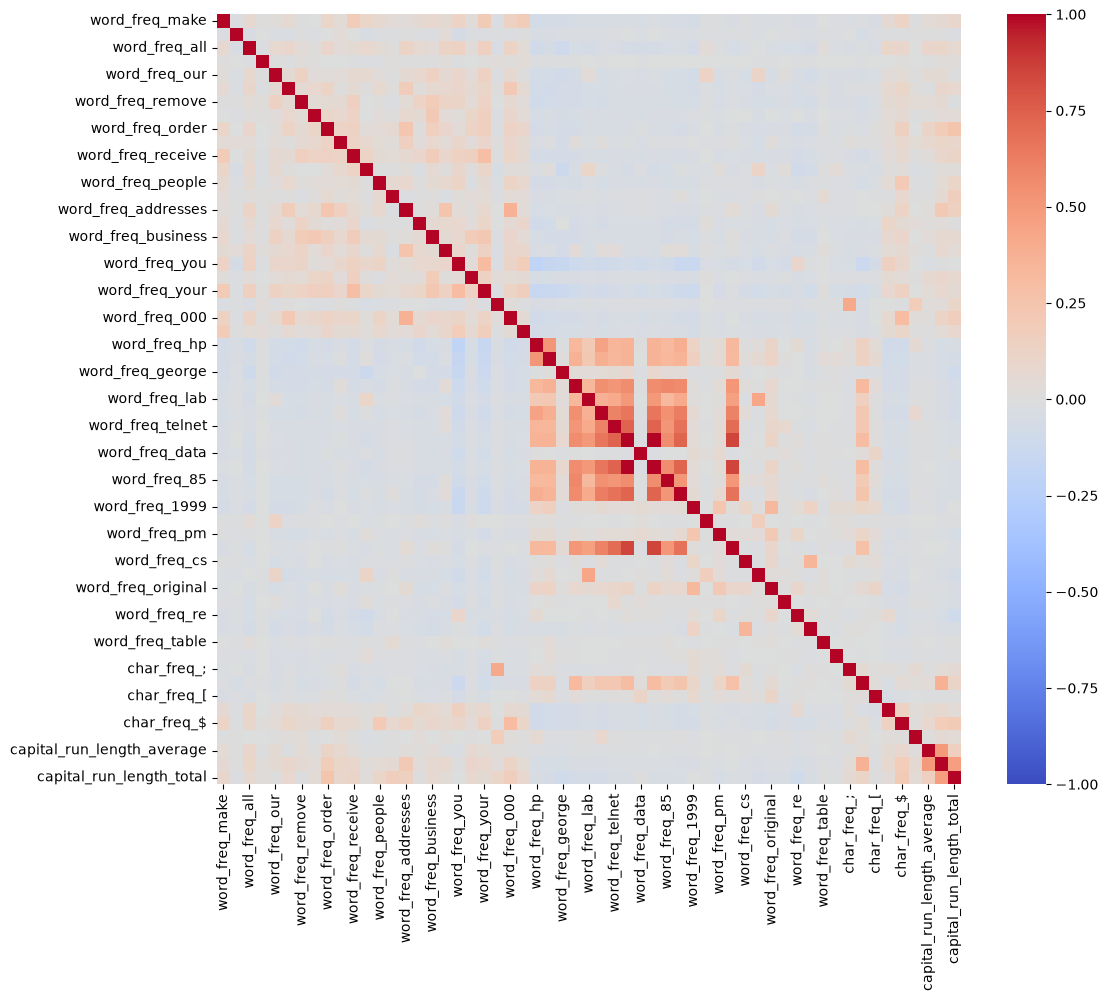

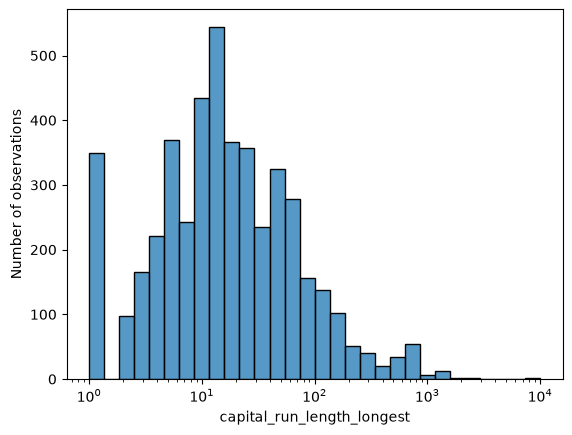

In [3]:
print(f"{X.shape[0]:,} observations, {X.shape[1]} features")
summary = mlw.summarize_dataset(X)
print("Missing feature values:", summary["missing"].sum())
display(summary.loc[['word_freq_415', 'word_freq_857', 'capital_run_length_longest']].round(3))

distribution = mlw.get_class_distribution(y)
display(distribution.style.format({"proportion": "{:.1%}"}))
mlw.plot_class_distribution(y, labels={0: "Non-spam", 1: "Spam"})
plt.show()

mlw.plot_correlation_matrix(X)
plt.show()

mlw.plot_feature_histogram(X["capital_run_length_longest"], log_scale=True)
plt.show()

**Commentaire :** Sur 4 601 e-mails, 1 813 sont des spams (39,4 %). Les deux classes sont bien représentées. Les fréquences `word_freq_415` et `word_freq_857` sont presque parfaitement corrélées (r ≈ 0,996). Elles pourraient donc apporter une information redondante lors de la sélection des variables.

La longueur de la plus longue suite de majuscules a une médiane de 15 caractères, mais atteint 9 989. L’axe logarithmique de l’histogramme permet de voir à la fois les suites courtes et les rares valeurs extrêmes.

## 2. Cleaning and split

In [4]:
rows_before = len(X)
exact_repeats = pd.concat([X, y], axis=1).duplicated().sum()
X, y = mlw.clean_dataset(X, y, drop_duplicates=False)
print(f"Rows before: {rows_before:,} | Rows after: {len(X):,} | Exact repeats: {exact_repeats:,}")

Rows before: 4,601 | Rows after: 4,601 | Exact repeats: 391


**Commentaire :** Les 391 répétitions exactes sont conservées. Deux e-mails distincts peuvent partager les 57 mêmes mesures et la même classe. Toutes les cibles sont renseignées et aucune variable ne nécessite d’imputation.

In [5]:
X_train, X_test, y_train, y_test = mlw.split_by_profile(X, y)
print(f"Training: {len(X_train):,} | Test: {len(X_test):,}")

Training: 3,680 | Test: 921


**Commentaire :** Le test porte sur des profils inédits. Tous les e-mails ayant les mêmes 57 mesures restent ensemble, même si leurs étiquettes diffèrent. La même contrainte est appliquée aux cinq plis de validation.

## 3. Preprocessing and feature selection

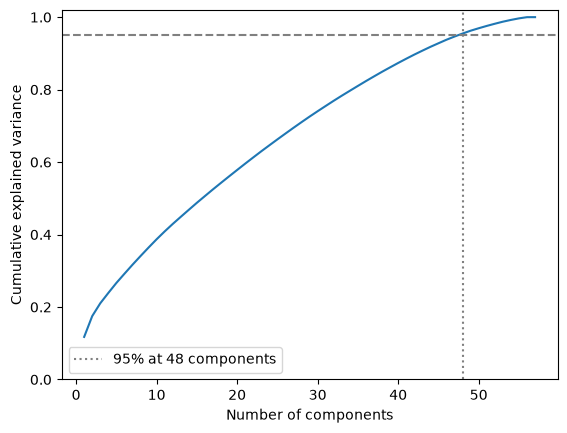

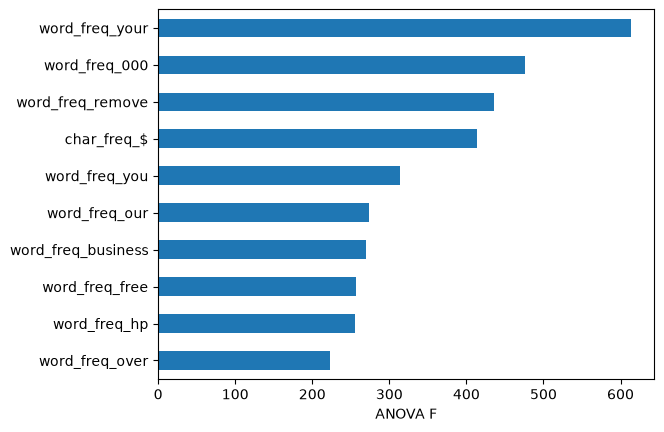

Highest ANOVA scores: word_freq_your, word_freq_000, word_freq_remove


In [6]:
mlw.plot_pca_explained_variance(X_train)
plt.show()
scores = mlw.compute_feature_scores(X_train, y_train)
mlw.plot_feature_scores(scores, top_n=10)
plt.show()
print("Highest ANOVA scores:", ", ".join(scores.index[:3]))

**Commentaire :** Il faut 48 composantes sur 57 pour conserver 95 % de la variance. La PCA compresse donc assez peu ces mesures. Le test F place notamment la fréquence de « your » en tête. Un score marginal élevé peut refléter le vocabulaire du corpus.

## 4. Model selection on training folds

Les cinq plis comparent une référence majoritaire, une régression logistique, un arbre de décision et un ensemble d’arbres entraînés séquentiellement (boosting). La médiane et la standardisation sont estimées dans chaque pli. Le meilleur réglage de chaque famille est ensuite réajusté sur tout l’entraînement.

In [7]:
SCORING = "f0.5"
cv_results, models = mlw.fit_candidates(
    X_train, y_train, scoring=SCORING,
    group_profiles=True,
)
winner = cv_results.iloc[0]["model"]
display(cv_results.round(4))
print("Selected on training folds:", winner)

,model,features,parameters,weights,CV mean,CV SD,precision,recall
10,Boosting,All features,{'model__max_leaf_nodes': 31},uniform,0.9349,0.0094,0.9333,0.9421
9,Boosting,All features,{'model__max_leaf_nodes': 7},uniform,0.9305,0.0048,0.9331,0.9207
3,Logistic,All features,{'model__C': 1.0},uniform,0.9093,0.0125,0.9165,0.8834
6,Logistic,PCA 95%,{'model__C': 1.0},uniform,0.9081,0.0105,0.9148,0.8848
1,Logistic,All features,{'model__C': 0.1},uniform,0.9077,0.0104,0.9184,0.8690
5,Logistic,PCA 95%,{'model__C': 0.1},uniform,0.9048,0.0135,0.9144,0.8697
2,Logistic,Top 28,{'model__C': 0.1},uniform,0.8944,0.0137,0.9118,0.8317
4,Logistic,Top 28,{'model__C': 1.0},uniform,0.8920,0.0163,0.9051,0.8441
8,Tree,All features,{'model__max_depth': 8},uniform,0.8792,0.0172,0.8870,0.8503
7,Tree,All features,{'model__max_depth': 3},uniform,0.8583,0.0187,0.8706,0.8131


Selected on training folds: Boosting


**Commentaire :** À régularisation comparable, la régression sur les 57 variables obtient un F₀,₅ moyen de 0,909. La PCA atteint 0,908 et la sélection de 28 variables au mieux 0,894. Garder la moitié des variables simplifie la collecte, avec une baisse du F₀,₅ sur ces plis. Les écarts-types décrivent la variation entre plis.

### Effet du découpage

À régression logistique identique, quel est l’effet du regroupement des profils ? Les deux protocoles sont comparés uniquement sur l’entraînement.

In [8]:
probe = mlw.build_pipeline(mlw.get_models()["Logistic"])
checks = {}
for protocol, grouped in [("Stratified", False), ("Grouped by profile", True)]:
    folds = mlw.training_folds(X_train, y_train, group_profiles=grouped)
    checks[protocol] = mlw.cross_validate_model(
        probe, X_train, y_train, scoring=["precision", "recall", "average_precision"], cv=folds,
    ).mean()
display(pd.DataFrame(checks).T.round(4))

,precision,recall,average_precision
Stratified,0.9207,0.8800,0.9508
Grouped by profile,0.9165,0.8834,0.9473


**Commentaire :** À modèle fixé, l’AP passe de 0,951 à 0,947 avec les groupes. Le changement de protocole a ici un effet modeste. Les plis diffèrent aussi dans leur composition, donc cet écart ne mesure pas à lui seul l’effet des répétitions.

### Seuil de blocage des courriels

On fixe une cible de précision de **98 %**. Parmi les seuils qui la satisfont sur les prédictions hors pli de l’entraînement, on retient celui qui retrouve le plus de spams. En cas d’égalité de rappel, on conserve le seuil le plus strict. Chaque profil est prédit par un modèle ajusté sur les autres groupes. Ces scores servent au réglage du seuil et les hyperparamètres proviennent de la validation précédente.

In [9]:
precision_target = 0.98
folds = mlw.training_folds(X_train, y_train, group_profiles=True)
oof_scores = mlw.out_of_fold_scores(models[winner], X_train, y_train, folds)
threshold = mlw.choose_precision_threshold(y_train, oof_scores, precision_target)
oof = mlw.compute_metrics(y_train, oof_scores >= threshold)
print(f"Frozen threshold: {threshold:.6f} | OOF precision: {oof['precision']:.2%} | OOF recall: {oof['recall']:.2%}")

Frozen threshold: 0.933425 | OOF precision: 98.01% | OOF recall: 81.72%


## 5. Held-out evaluation

,Majority,Logistic,Tree,Boosting
accuracy,0.6059,0.9164,0.9110,0.9555
balanced_accuracy,0.5000,0.9103,0.9000,0.9522
precision,0.0000,0.9040,0.9194,0.9497
recall,0.0000,0.8815,0.8485,0.9366
f1,0.0000,0.8926,0.8825,0.9431
f0.5,0.0000,0.8994,0.9043,0.9471
roc_auc,0.5000,0.9668,0.9266,0.9887
average_precision,0.3941,0.9350,0.8931,0.9846


,TN,FP,FN,TP
Majority,558,0,363,0
Logistic,524,34,43,320
Tree,531,27,55,308
Boosting,540,18,23,340


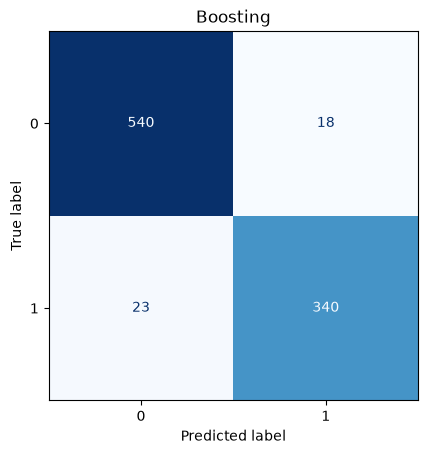

In [10]:
results = mlw.compare_models(models, X_test, y_test)
count_columns = ["TN", "FP", "FN", "TP"]
display(results.drop(columns=count_columns).T.round(4))
display(results[count_columns].astype(int))
mlw.plot_confusion_matrix(models[winner], X_test, y_test)
plt.title(winner)
plt.show()

In [11]:
adjusted = mlw.evaluate_model(models[winner], X_test, y_test, threshold=threshold)
policies = pd.DataFrame({"Default": results.loc[winner], "Frozen threshold": adjusted}).T
display(policies[["precision", "recall", "f0.5"]].round(4))
display(policies[["TN", "FP", "FN", "TP"]].astype(int))
flags = models[winner].predict_proba(X_test)[:, 1] >= threshold
low, high = mlw.grouped_precision_interval(y_test, flags, mlw.profile_groups(X_test))
print(f"Test precision, 95% profile-bootstrap interval: [{low:.2%}, {high:.2%}]")

,precision,recall,f0.5
Default,0.9497,0.9366,0.9471
Frozen threshold,0.9836,0.8264,0.9476


,TN,FP,FN,TP
Default,540,18,23,340
Frozen threshold,553,5,63,300


Test precision, 95% profile-bootstrap interval: [96.80%, 99.66%]


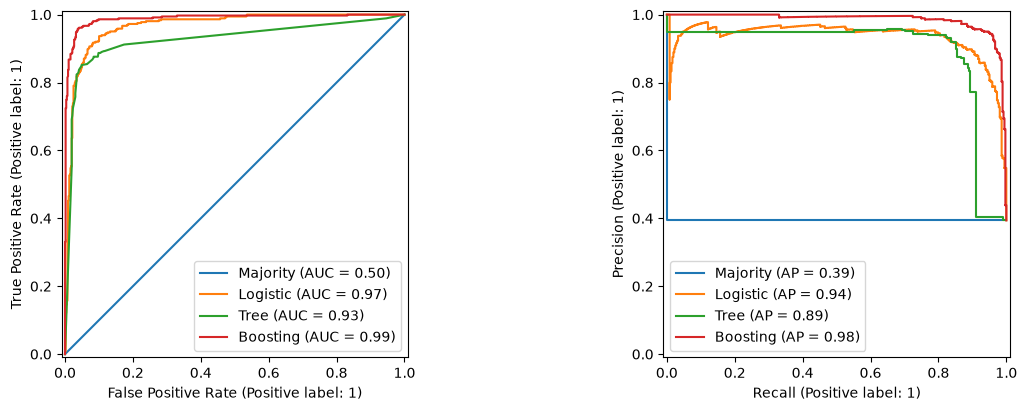

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
mlw.plot_roc_curves(models, X_test, y_test, ax=axes[0])
mlw.plot_precision_recall_curves(models, X_test, y_test, ax=axes[1])
plt.show()

## 6. Discussion

**Choix du modèle.** Le boosting à 31 feuilles au maximum par arbre obtient le meilleur F₀,₅ moyen en validation (0,935). Au seuil par défaut, il bloque 18 courriels légitimes et laisse passer 23 spams sur les 921 messages de test.

**Choix du seuil.** Pour un blocage automatique, je retiens le seuil fixé à 0,933425 (arrondi). La précision mesurée sur le test atteint 98,36 % (300 spams parmi 305 alertes). Le filtre épargne 13 courriels légitimes supplémentaires, au prix de 40 spams supplémentaires laissés passer. Sur cet échantillon, ce choix réduit le coût total dès que bloquer un courriel légitime coûte plus de 40/13 ≈ 3,1 fois le coût de laisser passer un spam.

**Portée.** En rééchantillonnant 2 000 fois les profils entiers du test à modèle et seuil fixes, l’intervalle à 95 % pour la précision va de 96,80 % à 99,66 %. La borne basse invite à vérifier la cible sur un autre corpus avant déploiement. Les mots et indicatifs associés aux auteurs du corpus de 1999 peuvent être beaucoup moins informatifs chez de nouveaux expéditeurs.